In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import make_moons, make_classification
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import accuracy_score

# Visual setup
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 11

print("Environment setup complete.")

Environment setup complete.


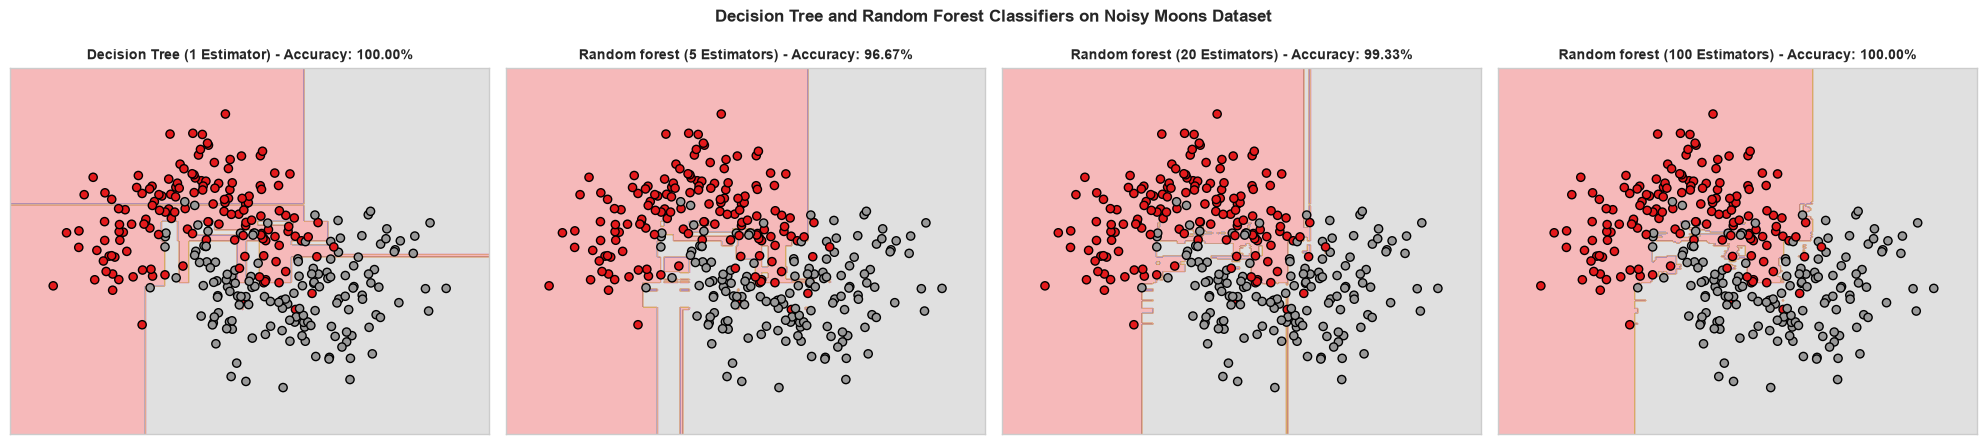

In [4]:
X_moons, y_moons = make_moons(n_samples=300, noise=0.3, random_state=42)
# make_moons generates a 2D dataset with two interleaving half circles (moons)

estimators_list = [1,5,20,100]

# X_moon[:,0] gives the x-coordinates of the points
# X_moon[:,1] gives the y-coordinates of the points
x_min, x_max = X_moons[:,0].min() - 0.5, X_moons[:,0].max() + 0.5
y_min, y_max = X_moons[:, 1].min() - 0.5, X_moons[:, 1].max() + 0.5
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 300),
                     np.linspace(y_min,y_max, 300))

fig, axes = plt.subplots(1, 4, figsize=(20, 4.5))

for idx, n_est in enumerate(estimators_list):
    if n_est == 1:
        model = DecisionTreeClassifier(random_state=42)
        title = "Decision Tree (1 Estimator)"
    else:
        model = RandomForestClassifier(n_estimators=n_est, random_state=42)
        title = f"Random forest ({n_est} Estimators)"
        
    model.fit(X_moons, y_moons)
    # ravel flattens the meshgrid arrays into 1D arrays for prediction
    # example of ravel :
    # xx.ravel() flattens the 2D array xx into a 1D array
    # yy.ravel() flattens the 2D array yy into a 1D array
    # np.c_ concatenates the flattened xx and yy arrays column-wise to create a 2D array of coordinates for prediction
    Z = model.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    
    ax = axes[idx]
    ax.contourf(xx, yy, Z, alpha=0.3,cmap="Set1")
    
    ax.scatter(X_moons[:, 0], X_moons[:, 1], c=y_moons, edgecolor='k',cmap="Set1",s=35)
    acc = accuracy_score(y_moons, model.predict(X_moons))
    ax.set_title(f"{title} - Accuracy: {acc * 100:.2f}%",fontsize=10,fontweight='bold')
    ax.set_xticks([])
    ax.set_yticks([])
    
plt.suptitle("Decision Tree and Random Forest Classifiers on Noisy Moons Dataset", fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()